In [ ]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats


import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [2]:
from config import *

In [3]:
convert_i_to_x = False
save_plots = True
mean_marker_size = 1
titles = True


In [4]:
def get_trajectory(graph,popsize,d):
    output_name = f"CC-N-{popsize}-geom-{graph}-d-{d}-r-{r}-tr-{timestop}"
    with open(f'{results_loc}{output_name}.txt', 'r') as file:
        lines = file.readlines()
        
    dist_data_lines = []
    for line in lines:
        if line.strip() and line[:len("Resident")]=="Resident":
            dist_data_lines.append(line.replace('\t',''))
    dist_data = [[subline.strip().split(' ')[1][:-1] for subline in line.strip().split(',')] for line in dist_data_lines ]
    columns = ['resident','mutant','vacant']
    df = pd.DataFrame(dist_data,columns = columns)
    df = df[['resident','vacant']]
    for col in ['resident','vacant']:
        df[col]=df[col].astype(float)/100*popsize
    traj = list(df['resident'])
    if convert_i_to_x:
        traj = [i/popsize for i in traj]
    if traj[-1]==0:
        return []
    else:
        return traj
    
def get_stats(traj):
    mean = np.mean(traj)
    std = np.std(traj)
    n = len(traj)
    alpha = 0.05
    z = 1.96
    ci_mean_lower = mean - z * std / np.sqrt(n)
    ci_mean_upper = mean + z * std / np.sqrt(n)

    df = (n - 1)
    chi2_lower = scipy.stats.chi2.ppf(1 - alpha/2, df)
    chi2_upper = scipy.stats.chi2.ppf(alpha/2, df)
    sample_var = std ** 2
    ci_var_lower = (df * sample_var) / chi2_lower
    ci_var_upper = (df * sample_var) / chi2_upper

    return {"mean":mean,"std":std,"ci":(ci_mean_lower,ci_mean_upper),"ci_var":(ci_var_lower,ci_var_upper)}



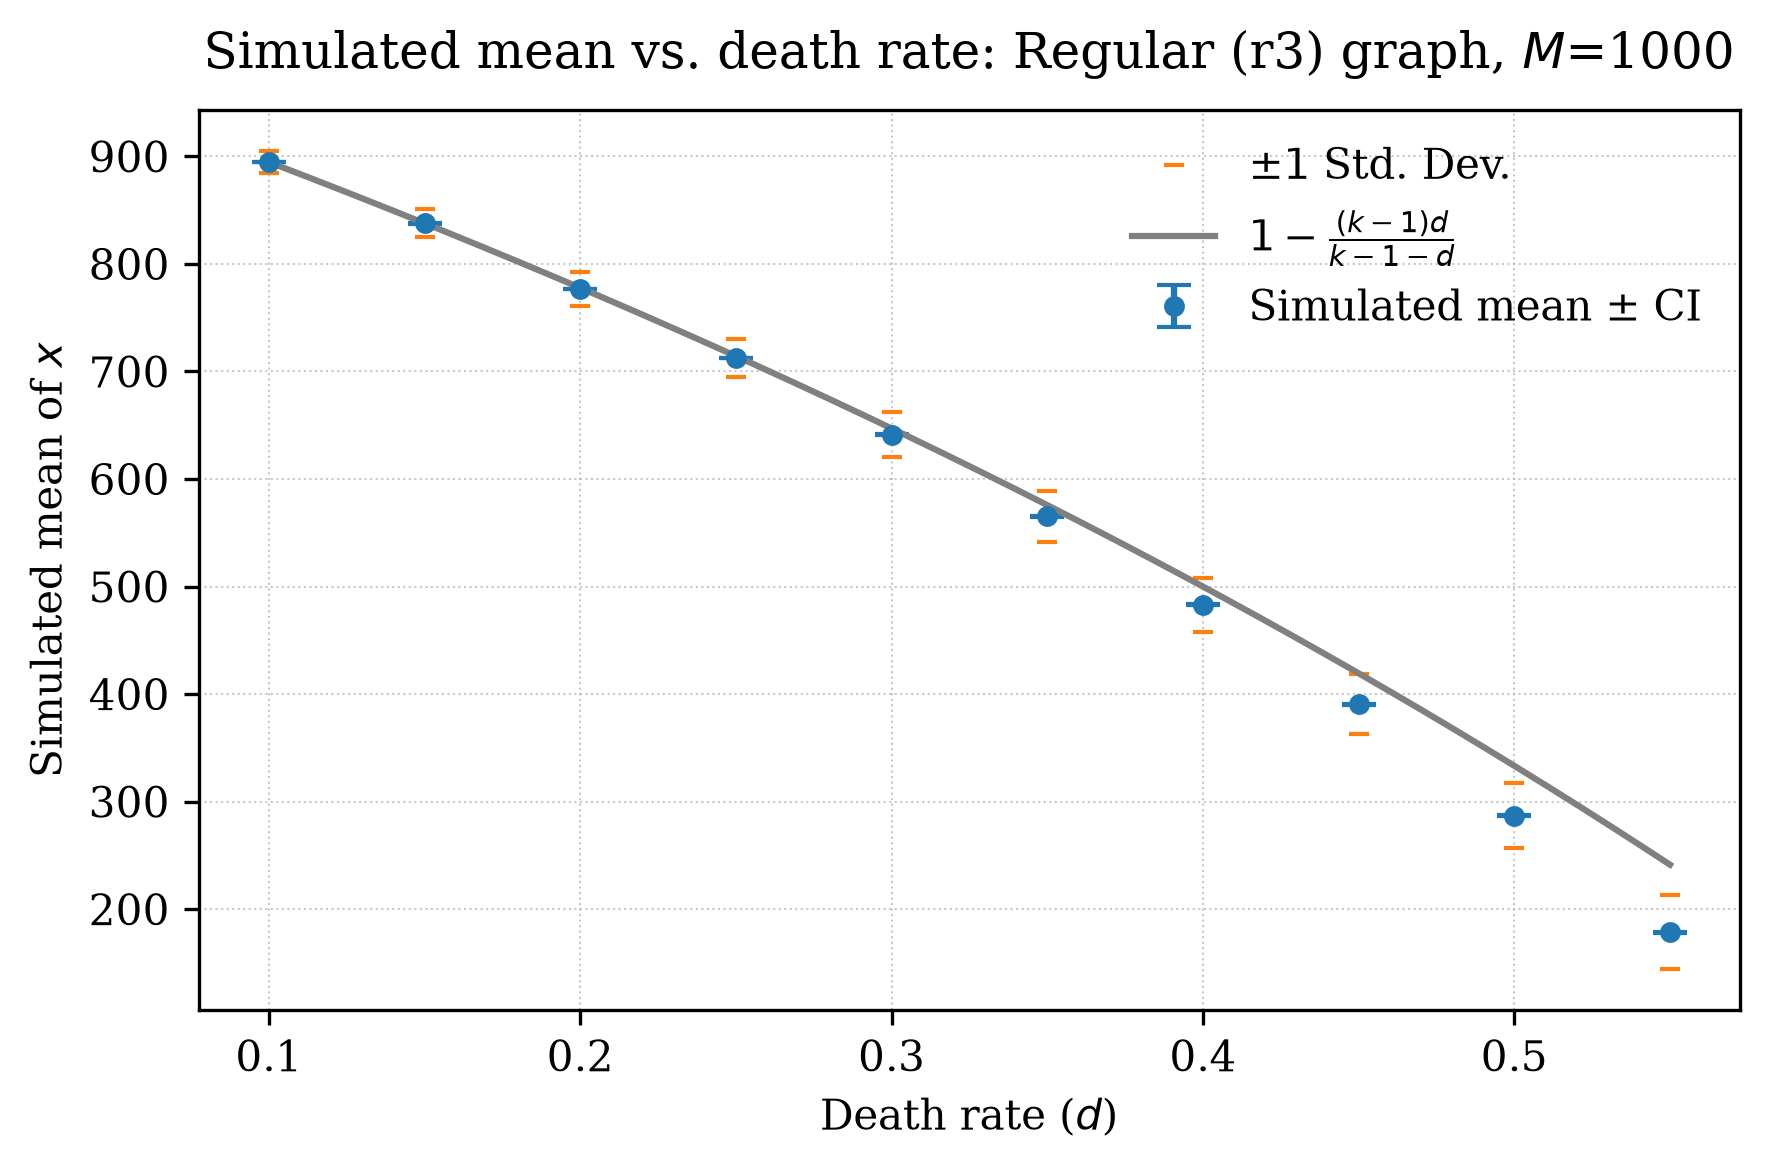

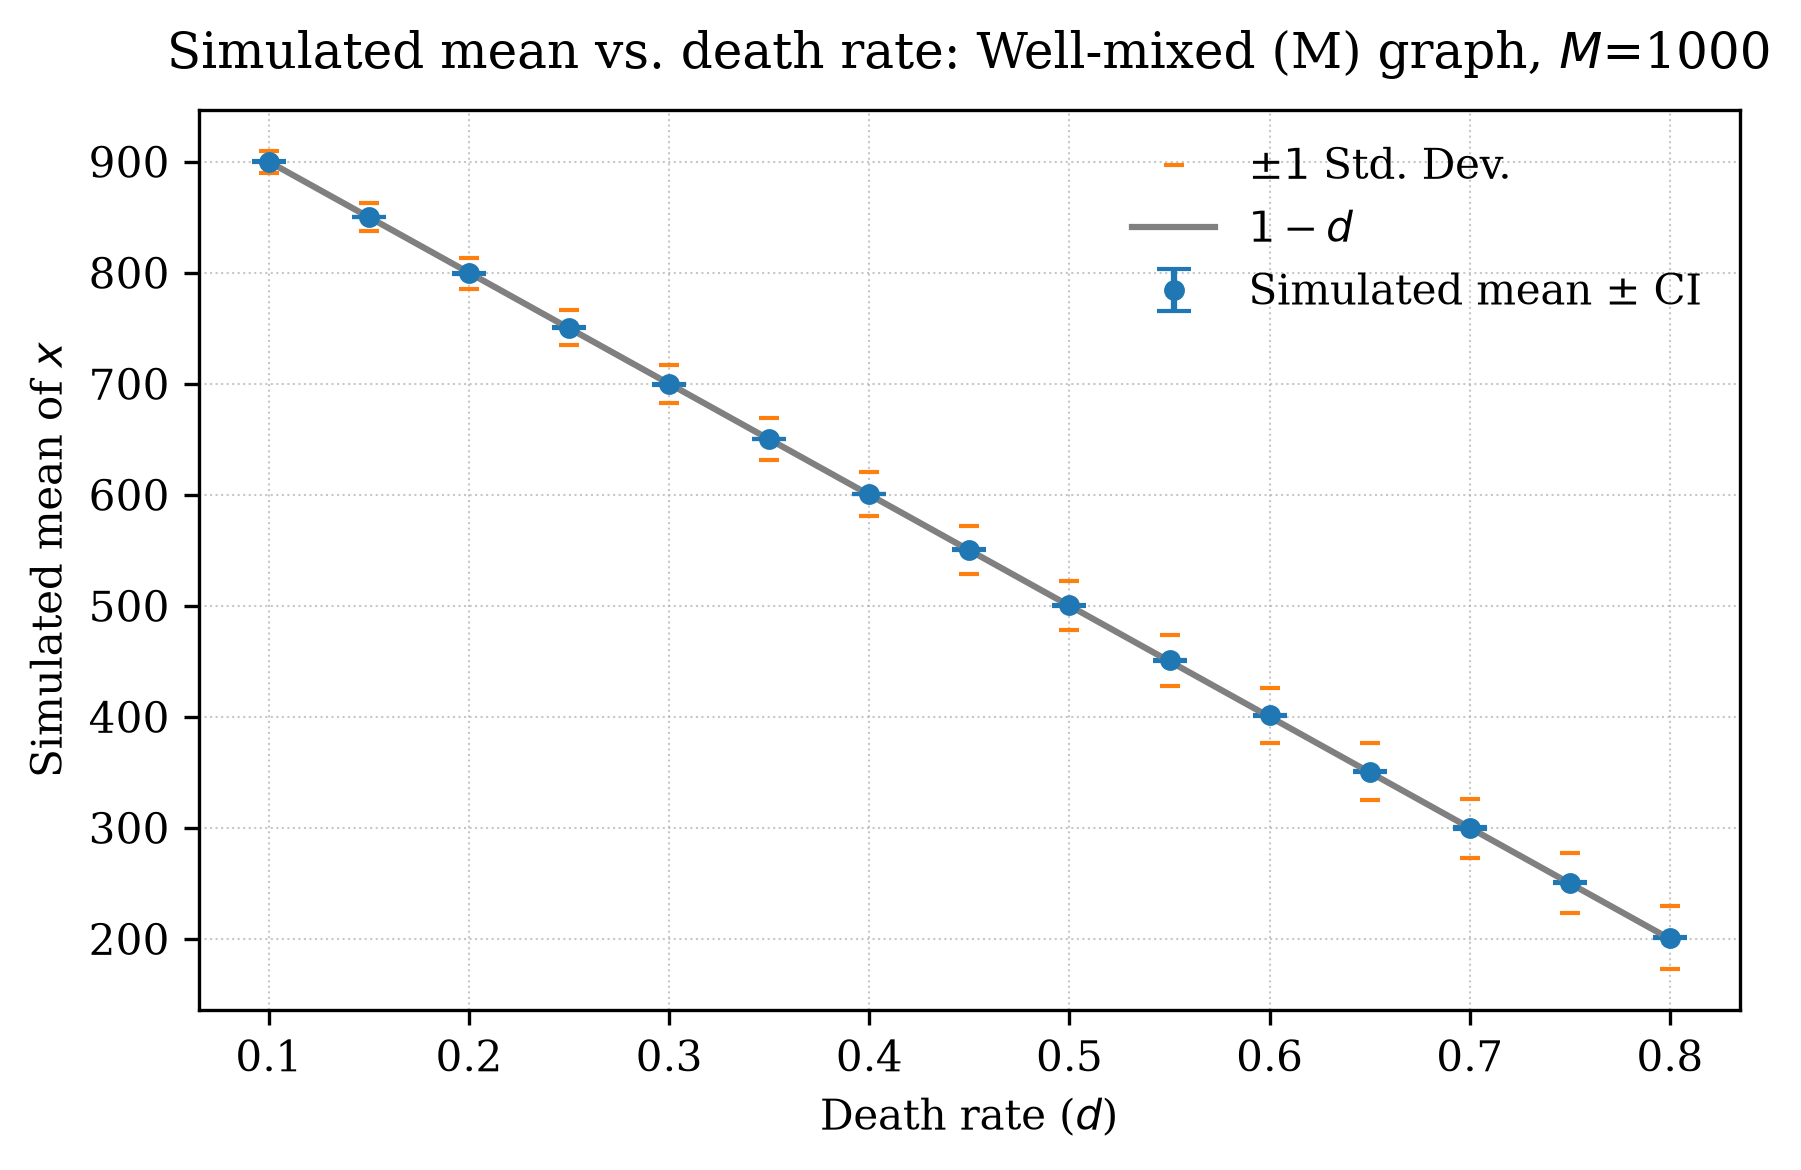

In [5]:

for graph in graphs:
    all_stats = []
    actual_deathrates = []
    for d in deathrates:
        try:
            traj = get_trajectory(graph['code'],single_N,d)
        
            if len(traj)>0:
                stats = get_stats(traj)
                all_stats.append(stats)
                actual_deathrates.append(d)
        except FileNotFoundError as e:
            print(f"No file for graph {graph['code']},N={single_N},d={d}, Error={e}")
        

    means = [r["mean"] for r in all_stats]
    ci_lowers = [r["mean"] - r["ci"][0] for r in all_stats]
    ci_uppers = [r["ci"][1] - r["mean"] for r in all_stats]
    stds = [r["std"] for r in all_stats]

    yerr = [ci_lowers, ci_uppers]

    plt.figure(figsize=(6, 4), dpi=300)
    plt.rcParams.update({
        "font.family": "serif",
        "font.size": 10
    })

    plt.errorbar(
        actual_deathrates,
        means,
        yerr=yerr,
        fmt='o',
        capsize=4,
        markersize=4,
        label=r"Simulated mean $\pm$ CI",
        color='tab:blue'
    )

    for idx, (x, mean, std) in enumerate(zip(actual_deathrates, means, stds)):
        plt.plot(
            [x, x], 
            [mean - std, mean + std], 
            marker='_', 
            markersize=5, 
            linestyle='None', 
            color='tab:orange', 
            label=r'$\pm 1$ Std. Dev.' if idx == 0 else None
        )

    second_ds = np.linspace(min(actual_deathrates), max(actual_deathrates), 1000)
    formula_colour = 'gray'

    if graph['name'] == "Well-mixed":
        if convert_i_to_x:
            expected_means = [1 - d for d in second_ds]
        else:
            expected_means = [single_N * (1 - d) for d in second_ds]
        plt.plot(second_ds, expected_means, label=r'$1 - d$', color=formula_colour)

    elif graph['name'] == "Regular":
        k = int(graph['code'][1:])
        if convert_i_to_x:
            expected_means = [1 - (k - 1) * d / (k - 1 - d) for d in second_ds]
        else:
            expected_means = [single_N * (1 - (k - 1) * d / (k - 1 - d)) for d in second_ds]
        plt.plot(second_ds, expected_means, label=r"$1-\frac{(k-1)d}{k-1-d}$", color=formula_colour)

    plt.xlabel(r"Death rate ($d$)")
    plt.ylabel("Simulated mean of $x$")
    if titles:
        plt.title(f"Simulated mean vs. death rate: {graph['name']} ({graph['code']}) graph, $M$={single_N}", pad=10)

    plt.legend(frameon=False)
    plt.grid(True, linestyle=':', linewidth=0.5, alpha=0.7)
    plt.tight_layout()

    filename = f"mean_vs_deathrate_{graph['name'].replace(' ', '_')}_{graph['code']}.pdf"
    if save_plots:
        plt.savefig(filename, bbox_inches='tight')

    plt.show()
